In [10]:
import os
from getpass import getpass

try:
    from dotenv import load_dotenv
    load_dotenv()
except Exception:
    pass

if not os.getenv("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"]=getpass("Enter GROQ_API_KEY")

if not os.getenv("TAVILY_API_KEY"):
    os.environ["TAVILY_API_KEY"]=getpass("Enter TAVILY_API_KEY")

if not os.getenv("PINECONE_API_KEY"):
    os.environ["PINECONE_API_KEY"]=getpass("Enter pinecone_API_KEY")

print("Groq is configured",bool(os.getenv("GROQ_API_KEY")))
print("Tavily is configured",bool(os.getenv("TAVILY_API_KEY")))
print("pinecone is configured",bool(os.getenv("PINECONE_API_KEY")))

Groq is configured True
Tavily is configured True
pinecone is configured True


#Load Document

In [21]:
from langchain_community.document_loaders import WebBaseLoader
source_url="https://docs.langchain.com/oss/python/langgraph/agentic-rag"

loader=WebBaseLoader(
    web_path=(source_url),
    requests_kwargs={
        "headers":{
            "User-Agent":"College-Rag-Bot/1.0"
        }
    }
)
raw_doc=loader.load()
print("Length of the documents",len(raw_doc))
print("source",raw_doc[0].metadata.get("source"))
print(raw_doc[0].page_content[:1500])


Length of the documents 1
source https://docs.langchain.com/oss/python/langgraph/agentic-rag
Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentInterrupt is coming to London on October 13! Get ticketsDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsLangChainMulti-agentLangGraphCustom RAG agentCustom SQL agentConceptual overviewsLangChain vs. LangGraph vs. Deep AgentsProviders and modelsComponent architectureMemoryContextGraph APIFunctional APIAdditional resourcesUse docs programmaticallyLangChain AcademyCase studiesGet helpOn this pageConceptsSetupSet up LangSmithPreprocess documentsCreate a r

Split Document

In [22]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitter=RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=150,
    add_start_index=True,
)

chunks=splitter.split_documents(raw_doc)
print("Total_chnks",len(chunks))
print(chunks[0].page_content[:500])

Total_chnks 28
Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentInterrupt is coming to London on October 13! Get ticketsDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegration


Embedding

In [2]:
from langchain_huggingface import HuggingFaceEmbeddings

embedding=HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

sample_vector=embedding.embed_query("what is agentic rag")
print("Embedding dimession",len(sample_vector))

d:\Au_chatbot\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1446.72it/s]


Embedding dimession 384


In [ ]:
from pinecone import Pinecone,ServerlessSpec
from langchain_pinecone import PineconeVectorStore

Index_name="industry-rag"
Name_space="industryrag-chatbot"

pc=Pinecone(api_key=os.environ["PINECONE_API_KEY"])

pc.create_index(
    name=Index_name,
    dimension=384,
    metric="cosine",
    spec=ServerlessSpec(
        cloud="aws",
        region="us-east-1"
    )

)


In [ ]:
vectorStore=PineconeVectorStore.from_documents(
    documents=chunks,
    embedding=embedding,
    index_name=Index_name,
    namespace=Name_space
)



In [36]:
retriver=vectorStore.as_retriever(
    search_kwargs={
        "k":4,
        "namespace":Name_space
    }
)

In [3]:
import os
from pinecone import Pinecone,ServerlessSpec
from langchain_pinecone import PineconeVectorStore

Index_name="industry-rag"
Name_space="industryrag-chatbot"

pc=Pinecone(api_key=os.environ["PINECONE_API_KEY"])

index=pc.Index(Index_name)

vectorStore=PineconeVectorStore(
    index=index,
    embedding=embedding,
    namespace=Name_space
)

retriever=vectorStore.as_retriever(
    search_kwargs={
        "k":2,
    }
)

print("Existinig pinecone executed")

Existinig pinecone executed


In [4]:
text_question = "what happens if the retrieved documents are not available in agentic rag"

kb_docs = retriever.invoke(text_question)

print("Number of documents retrieved:", len(kb_docs))

for i, content in enumerate(kb_docs):
    print(f"\n--- Document {i + 1} ---")
    print("Source:", content.metadata.get("source"))
    print(content.page_content[:700])

Number of documents retrieved: 2

--- Document 1 ---
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag
Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentInterrupt is coming to London on October 13! Get ticketsDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsLangChainMulti-agentLangGraphCustom RAG agentCustom SQL agentConceptual overviewsLangChain vs. LangGraph vs. Deep AgentsProviders and modelsComp

--- Document 2 ---
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag
pageConceptsSetupSet up LangSmithPreprocess documentsCreate a retriever toolGenerate a que

Initialize llm

In [5]:
from langchain_groq import ChatGroq
llm=ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

print("\n",llm.invoke("what is rag in one senetence").content)


 Retrieval‑Augmented Generation (RAG) is an AI approach that combines a language model with a searchable external knowledge base, retrieving relevant documents at inference time to augment and improve the model’s generated responses.


Tavily web search

In [6]:
from langchain_tavily import TavilySearch
web_search=TavilySearch(
    max_results=5,
    topic="general",
    include_answer=True,
    include_raw_content=False
)

Structure Decision

In [7]:
from langchain_core.documents import Document
from typing_extensions import TypedDict
from pydantic import BaseModel,Field
from typing import  Literal,Optional,List

class RouteDecision(BaseModel):
    route:Literal["kb","direct"]=Field(
        description="use Kb for available in agentic rag doc; direct for greeting/simple chat "
    )

class EvidenceGrade(BaseModel):
    grade:Literal["good","weak"]=Field(
        description="good mean evidence can answere the question ; weak means not enough evidence"
    )


class AgentState(TypedDict):
    question: str
    current_query: str
    kb_docs: list[Document]
    web_results: str
    kb_grade: str
    web_grade: str
    answer: str
    source_used: str
    citation: list[str]
    retry_count: int


Route question

In [8]:
router_llm=llm.with_structured_output(RouteDecision,method="json_mode")
def route_questions(state: AgentState):
    question = state["question"]

    decision = router_llm.invoke(f"""
You are a router for an Agentic RAG assistant.

Route to "kb" if the user asks about:
- Agentic RAG
- LangGraph Agentic RAG workflow
- retrieval grading
- query rewriting
- RAG architecture
- retriever tools
- web fallback in RAG

Route to "direct" only for greetings, thanks, or very simple conversation.

Question:
{question}

Return your response as valid JSON.
Example:
{{"route": "kb"}}
""")
    print("[Router]", decision.route)

    return {
        "current_query": question,
        "source_used": decision.route,
    }
def route_after_router(state: AgentState) -> Literal["retrieve_kb", "direct_answer"]:
    if state["source_used"] == "kb":
        return "retrieve_kb"
    return "direct_answer"

Retrive_kb

In [9]:
def retrieve_kb(state: AgentState):
    query = state["current_query"]
    docs = retriever.invoke(query)

    print(f"[KB Retriever] Query: {query}")
    print(f"[KB Retriever] Retrieved: {len(docs)} chunks")

    return {"kb_docs": docs}


kb_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")

def grade_kb_evidence(state: AgentState):
    question = state["question"]

    context = "\n\n".join(
        f"Source: {doc.metadata.get('source')}\n{doc.page_content}"
        for doc in state["kb_docs"]
    )

    grade = kb_grader_llm.invoke(f'''
You are an evidence grader.

Question:
{question}

Private KB evidence:
{context}

Can this private KB evidence answer the question?
Return "good" if it can answer.
Return "weak" if it cannot answer or is incomplete.

Return your response as valid JSON.
Example:
{{"grade": "good"}}
''')

    print("[KB Grader]", grade.grade)

    return {"kb_grade": grade.grade}


def decide_after_kb_grade(state: AgentState) -> Literal["generate_from_kb", "search_web"]:
    if state["kb_grade"] == "good":
        return "generate_from_kb"
    return "search_web"

In [10]:
def search_web(state: AgentState):
    query = state["current_query"]

    print(f"[Tavily Search] Query: {query}")

    result = web_search.invoke({"query": query})

    # Tavily can return dict/list structures depending on package version.
    # Convert it into readable text for grading and generation.
    if isinstance(result, dict):
        answer = result.get("answer", "")
        results = result.get("results", [])
        lines = []
        if answer:
            lines.append(f"Tavily answer: {answer}")

        for item in results:
            title = item.get("title", "")
            url = item.get("url", "")
            content = item.get("content", "")

            if title or content:
                lines.append(f"Title: {title}\nURL: {url}\nContent: {content}")

        web_text = "\n\n".join(lines) if lines else str(result)
    else:
        web_text = str(result)

    print("[Tavily Search] Result characters:", len(web_text))

    return {
        "web_results": web_text,
        "source_used": "web",
    }

In [11]:
web_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")

def grade_web_evidence(state: AgentState):
    question = state["question"]
    web_results = state["web_results"]

    grade = web_grader_llm.invoke(f'''
You are an evidence grader.

Question:
{question}

Web search evidence:
{web_results}

Can this web evidence answer the question?
Return "good" if it can answer.
Return "weak" if it cannot answer or is incomplete.

Return your response as valid JSON.
Example:
{{"grade": "good"}}
''')

    print("[Web Grader]", grade.grade)

    return {"web_grade": grade.grade}

MAX_RETRIES = 1

def decide_after_web_grade(state: AgentState) -> Literal["generate_from_web", "rewrite_query", "answer_insufficient"]:
    if state["web_grade"] == "good":
        return "generate_from_web"
    
    if state["retry_count"] < MAX_RETRIES:
        return "rewrite_query"
    
    return "answer_insufficient"

In [12]:
from langchain_core.messages import HumanMessage

def rewrite_query(state: AgentState):
    question = state["question"]
    retry_count = state["retry_count"] + 1

    rewritten = llm.invoke(f'''
Rewrite the question for better retrieval and web search.

Rules:
- Preserve original intent.
- Make it specific and search-friendly.
- Do not answer.
- Return only the rewritten query.

Original question:
{question}
''').content.strip()

    print("[Rewriter]", rewritten)

    return {
        "current_query": rewritten,
        "retry_count": retry_count,
    }

In [13]:
def generate_from_kb(state: AgentState):
    question = state["question"]

    context = "\n\n".join(
        f"[KB Source: {doc.metadata.get('source')}]\n{doc.page_content}"
        for doc in state["kb_docs"]
    )

    answer = llm.invoke(f'''
You are a technical instructor.

Answer using ONLY the private KB context.

Rules:
- Beginner-friendly explanation.
- Do not invent unsupported details.
- Mention that the answer is based on the private KB.
- Include source links.

Context:
{context}

Question:
{question}
''')

    print("[Generate KB]", answer.content[:100], "...")

    return {
        "answer": answer.content,
        "source_used": "private_kb",
        "citation": [doc.metadata.get("source") for doc in state["kb_docs"]],
    }

In [14]:
def generate_from_web(state: AgentState):
    question = state["question"]
    web_results = state["web_results"]

    answer = llm.invoke(f'''
You are a technical instructor.

Answer using ONLY the provided web search results.

Rules:
- Beginner-friendly explanation.
- Do not invent unsupported details.
- Mention that the answer is based on external web search.
- Include source links/references where applicable.

Web Search Results:
{web_results}

Question:
{question}
''')

    print("[Generate Web]", answer.content[:100], "...")

    return {
        "answer": answer.content,
        "source_used": "web_search",
        "citation": [state.get("web_results", "")]
    }

In [15]:
def direct_answer(state: AgentState):
    question = state["question"]

    answer = llm.invoke(f'''
Respond briefly and naturally.

Message:
{question}
''').content

    return {
        "answer": answer,
        "source_used": "direct",
    }

In [16]:
def answer_insufficient(state: AgentState):
    answer = (
        "I could not find enough reliable evidence in the "
        "private knowledge base or web search results to answer "
        "the question confidently."
    )

    return {
        "answer": answer,
        "source_used": "insufficient",
    }

In [17]:
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(AgentState)

# Add nodes
workflow.add_node("route_questions", route_questions)
workflow.add_node("retrieve_kb", retrieve_kb)
workflow.add_node("grade_kb_evidence", grade_kb_evidence)
workflow.add_node("search_web", search_web)
workflow.add_node("grade_web_evidence", grade_web_evidence)
workflow.add_node("rewrite_query", rewrite_query)
workflow.add_node("generate_from_kb", generate_from_kb)
workflow.add_node("generate_from_web", generate_from_web)
workflow.add_node("direct_answer", direct_answer)
workflow.add_node("answer_insufficient", answer_insufficient)

# Add edges & conditional edges
workflow.add_edge(START, "route_questions")

workflow.add_conditional_edges(
    "route_questions",
    route_after_router,
    {
        "retrieve_kb": "retrieve_kb",
        "direct_answer": "direct_answer",
    }
)

workflow.add_edge("retrieve_kb", "grade_kb_evidence")

workflow.add_conditional_edges(
    "grade_kb_evidence",
    decide_after_kb_grade,
    {
        "generate_from_kb": "generate_from_kb",
        "search_web": "search_web",
    }
)

workflow.add_edge("search_web", "grade_web_evidence")

workflow.add_conditional_edges(
    "grade_web_evidence",
    decide_after_web_grade,
    {
        "generate_from_web": "generate_from_web",
        "rewrite_query": "rewrite_query",
        "answer_insufficient": "answer_insufficient",
    }
)

workflow.add_edge("rewrite_query", "search_web")

workflow.add_edge("generate_from_kb", END)
workflow.add_edge("generate_from_web", END)
workflow.add_edge("direct_answer", END)
workflow.add_edge("answer_insufficient", END)

app = workflow.compile()

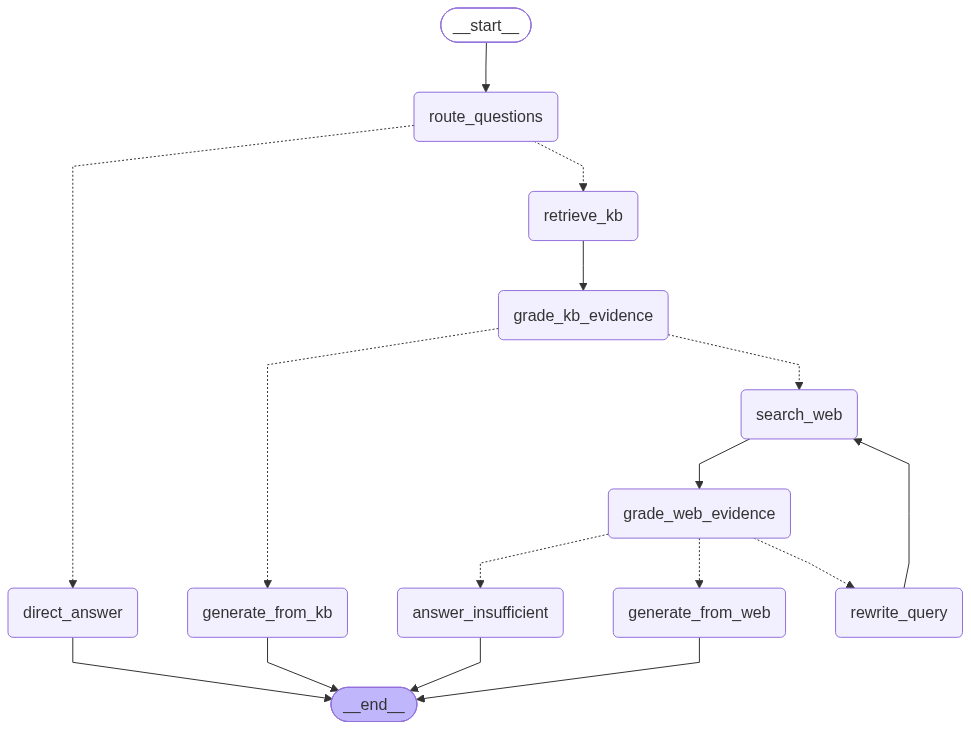

In [18]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [19]:
def ask_agent(question: str):
    initial_state: AgentState = {
        "question": question,
        "current_query": question,
        "kb_docs": [],
        "web_results": "",
        "kb_grade": "",
        "web_grade": "",
        "answer": "",
        "source_used": "",
        "retry_count": 0,
    }

    result = app.invoke(initial_state)

    print("\n" + "=" * 90)
    print("QUESTION:")
    print(question)

    print("\nSOURCE USED:")
    print(result["source_used"])

    print("\nFINAL ANSWER:")
    print(result["answer"])

    print("=" * 90)

    return result

In [23]:
result=ask_agent("what is the langgraph and whwhyen to use this")

[Router] kb
[KB Retriever] Query: what is the langgraph and whwhyen to use this
[KB Retriever] Retrieved: 2 chunks
[KB Grader] good
[Generate KB] **Answer (based on the private LangChain KB)**  

**What is LangGraph?**  
LangGraph is a collection ...

QUESTION:
what is the langgraph and whwhyen to use this

SOURCE USED:
private_kb

FINAL ANSWER:
**Answer (based on the private LangChain KB)**  

**What is LangGraph?**  
LangGraph is a collection of low‑level “primitives” that LangChain uses to build agents. Think of it as the building blocks for creating custom, programmable workflows (agents) that can retrieve information, reason, and generate responses. LangChain already provides ready‑made agents built on these primitives, but when you need more control or want to tailor the behavior of an agent, you can work directly with LangGraph.

**When should you use LangGraph?**  
- **Deep customization:** If the built‑in LangChain agents don’t fit your exact use‑case (e.g., you need a special